# 11 — Proyección del Parque Tunari con la regresión binomial negativa estacional

## Para qué sirve este notebook

Es el notebook **de trabajo para las proyecciones**. Toma la serie mensual armonizada del Parque Tunari, la revisa, ajusta el modelo elegido
(**regresión binomial negativa estacional**, el «modelo 2» del notebook 09), mide su desempeño con **MAE, RMSE, MAPE, sMAPE, WAPE, sesgo y cobertura**,
revisa que el modelo no tenga fallas y produce el pronóstico hasta **diciembre de 2031** (62 meses desde noviembre de 2026) con bandas de incertidumbre, y explica cómo entra **NOAA-20** en lugar de Suomi-NPP desde noviembre de 2026.

**Por qué este modelo:** en la comparación de los notebooks 09 y 10 fue el de menor error entre los que se pueden usar de verdad
(SARIMA, SARIMAX, Prophet y LSTM no lo mejoraron; el único mejor usaba el clima real del mes pronosticado, algo que no se conoce de antemano).
No usa clima, es simple de explicar y es la misma familia de modelos que usan nuestras alertas.

## Qué se pronostica

- **`indice_para_alertas`** de la tabla `serie_mensual` (área `parque-tunari`): celdas-día por mes en unidades **MODIS-equivalentes**
  (hasta enero de 2012 es MODIS; después, VIIRS Suomi-NPP ÷ factor 2,8715).
- El modelo se ajusta sobre el **conteo** (`conteo_base_alertas`) y el factor entra como compensación; el pronóstico queda en la misma unidad que el índice.
- **Una detección no es un incendio:** se pronostica el nivel de actividad de calor, no incendios concretos.

## Cómo se evalúa

**Validación rodante:** para cada año de 2019 a 2026 se entrena **solo con datos hasta octubre del año anterior** y se pronostica ese año.
Es la misma situación de 2027 (hoy hay datos hasta octubre de 2026), así que el error medido se parece al esperable.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()
PAQUETE = ROOT / "entrega_backend" / "datos"
SALIDA = ROOT / "DATOS_PROCESADOS" / "pronostico"
SALIDA.mkdir(parents=True, exist_ok=True)
AREA = "parque-tunari"
FACTOR = float(pd.read_csv(PAQUETE / "parametros.csv").set_index("clave").loc["factor_viirs_por_modis", "valor"])
RNG = np.random.default_rng(42)

serie = pd.read_csv(PAQUETE / "serie_mensual.csv", parse_dates=["mes"])
t = serie[serie.area_id == AREA].sort_values("mes").set_index("mes").asfreq("MS")
t["factor_epoca"] = np.where(t.era == "MODIS_solo", 1.0, FACTOR)
ORIGEN = t.index.max()

print(f"Factor VIIRS/MODIS: {FACTOR}")
print(f"Meses: {len(t)} ({t.index.min():%Y-%m} a {t.index.max():%Y-%m}); faltantes: {int(t.indice_para_alertas.isna().sum())}")
print("Máx |índice − conteo/factor| =", float((t.indice_para_alertas - t.conteo_base_alertas / t.factor_epoca).abs().max()))
t[["era", "conteo_base_alertas", "factor_epoca", "indice_para_alertas"]].tail(6)

Factor VIIRS/MODIS: 2.8715
Meses: 303 (2001-08 a 2026-10); faltantes: 0
Máx |índice − conteo/factor| = 0.00016724306130555533


,era,conteo_base_alertas,factor_epoca,indice_para_alertas
mes,,,,
2026-05-01,MODIS+VIIRS-SNPP,2.0,2.8715,0.696497
2026-06-01,MODIS+VIIRS-SNPP,14.0,2.8715,4.875479
2026-07-01,MODIS+VIIRS-SNPP,30.0,2.8715,10.447454
2026-08-01,MODIS+VIIRS-SNPP,39.0,2.8715,13.581691
2026-09-01,MODIS+VIIRS-SNPP,26.0,2.8715,9.054460
2026-10-01,MODIS+VIIRS-SNPP,23.0,2.8715,8.009715


## 1. Control de calidad: ¿qué hay detrás de los últimos meses?

Los meses de **agosto a octubre de 2026** se armaron con datos **NRT** (provisionales, en tiempo casi real). Aquí se comprueba, con las detecciones del paquete,
que el índice mensual **sí incluye** esos datos y cuánto dependería de ellos. Se cuentan celdas-día (una celda de 1 km con detección en un día, contada una vez) de Suomi-NPP en el parque.

In [2]:
det = pd.read_csv(PAQUETE / "detecciones.csv", usecols=["fecha_bo", "plataforma", "cell_id", "en_parque_tunari", "origen_dato"])
det = det[det.en_parque_tunari & (det.plataforma == "Suomi-NPP") & (det.fecha_bo >= "2026-05-01")].copy()
det["mes"] = pd.to_datetime(det.fecha_bo.str[:7] + "-01")


def celdas_dia(x):
    return x[["cell_id", "fecha_bo", "mes"]].drop_duplicates().groupby("mes").size()


control = pd.DataFrame({
    "celdas-día con NRT": celdas_dia(det),
    "celdas-día solo estándar": celdas_dia(det[det.origen_dato != "NRT"]),
    "conteo usado en la serie": t.loc["2026-05-01":, "conteo_base_alertas"],
}).fillna(0).astype(int)
control["¿coincide con la serie (con NRT)?"] = control["celdas-día con NRT"] == control["conteo usado en la serie"]
control

,celdas-día con NRT,celdas-día solo estándar,conteo usado en la serie,¿coincide con la serie (con NRT)?
mes,,,,
2026-05-01,2,2,2,True
2026-06-01,14,14,14,True
2026-07-01,30,30,30,True
2026-08-01,39,0,39,True
2026-09-01,26,0,26,True
2026-10-01,23,0,23,True


**Lectura:** si la columna «con NRT» coincide con la serie, el índice de esos meses **incluye datos provisionales**. Cuando NASA publique el dato estándar, esos meses pueden cambiar un poco;
al final del notebook se prueba cuánto cambiaría la proyección si se ignoran esos tres meses.

## 2. Tratamiento de la serie

Se revisa lo que importa para elegir el modelo: forma de la temporada, ceros, sobredispersión, tendencia y estacionariedad.

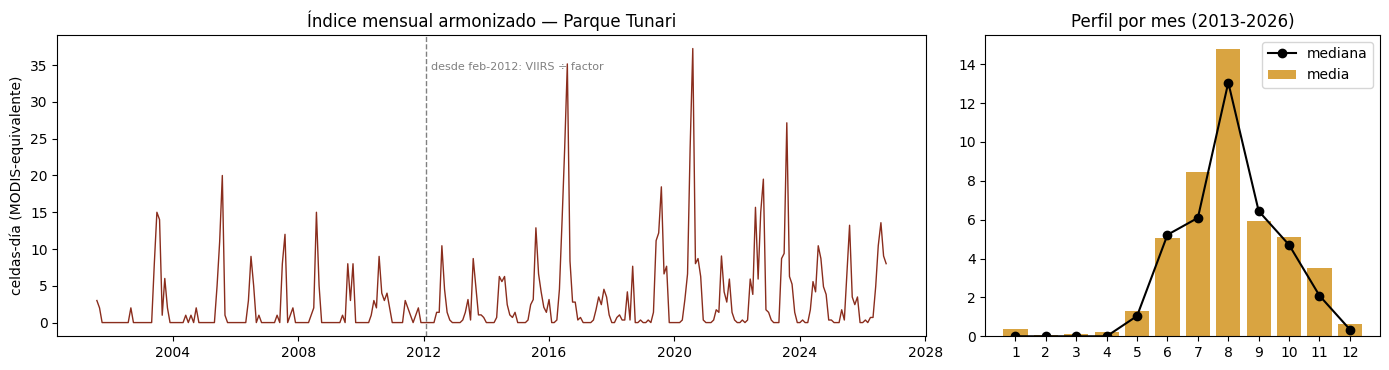

Índice anual 2013-2025: {2013: 21.6, 2014: 24.4, 2015: 33.1, 2016: 95.1, 2017: 17.8, 2018: 15.0, 2019: 57.8, 2020: 94.4, 2021: 27.2, 2022: 68.3, 2023: 59.9, 2024: 40.0, 2025: 31.7}
Meses con índice 0 desde 2013: 29%


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(t.index, t.indice_para_alertas, lw=1, color="#8a2d1d")
ax[0].axvline(pd.Timestamp("2012-02-01"), color="gray", ls="--", lw=1)
ax[0].text(pd.Timestamp("2012-04-01"), t.indice_para_alertas.max() * 0.92, "desde feb-2012: VIIRS ÷ factor", fontsize=8, color="gray")
ax[0].set_title("Índice mensual armonizado — Parque Tunari"); ax[0].set_ylabel("celdas-día (MODIS-equivalente)")
h = t[t.index.year >= 2013]
perfil = h.groupby(h.index.month).indice_para_alertas.agg(["median", "mean"])
ax[1].bar(perfil.index, perfil["mean"], color="#d9a441", label="media"); ax[1].plot(perfil.index, perfil["median"], "ko-", label="mediana")
ax[1].set_title("Perfil por mes (2013-2026)"); ax[1].set_xticks(range(1, 13)); ax[1].legend()
plt.tight_layout(); plt.show()

y = t.indice_para_alertas
anual = y[y.index.year.isin(range(2013, 2026))].groupby(lambda d: d.year).sum()
print("Índice anual 2013-2025:", anual.round(1).to_dict())
print(f"Meses con índice 0 desde 2013: {(h.indice_para_alertas == 0).mean():.0%}")

In [4]:
# Sobredispersión: en un conteo de Poisson la varianza sería igual a la media. Aquí es mucho mayor -> se usa la binomial negativa.
c = h.conteo_base_alertas
resumen_mes = c.groupby(c.index.month).agg(media="mean", varianza="var")
resumen_mes["varianza / media"] = (resumen_mes.varianza / resumen_mes.media).round(1)
print(resumen_mes.round(1).to_string())

# Tendencia: ¿el nivel anual sube o baja? (Mann-Kendall vía tau de Kendall y pendiente de Theil-Sen)
tau, p_tau = stats.kendalltau(anual.index, anual.values)
pend, inter, lo, hi = stats.theilslopes(anual.values, anual.index.values)
print(f"\nTendencia anual 2013-2025: tau = {tau:.2f}, p = {p_tau:.3f}; pendiente de Sen = {pend:+.1f} celdas-día/año (IC 95 %: {lo:+.1f} a {hi:+.1f})")

# Estacionariedad de la serie en logaritmo
ylog = np.log1p(y.dropna())
adf = adfuller(ylog, autolag="AIC")
kp = kpss(ylog, regression="c", nlags="auto")
print(f"Dickey-Fuller aumentado (H0: raíz unitaria): estadístico {adf[0]:.2f}, p = {adf[1]:.4f}")
print(f"KPSS (H0: estacionaria): estadístico {kp[0]:.2f}, p ≈ {kp[1]:.3f}")

     media  varianza  varianza / media
mes                                   
1      1.1       6.4               5.6
2      0.2       0.2               0.8
3      0.3       0.4               1.3
4      0.6       0.9               1.3
5      3.7      13.5               3.6
6     14.6     142.4               9.8
7     24.2     438.6              18.1
8     42.4    1061.0              25.0
9     17.1      46.4               2.7
10    14.6     126.1               8.6
11    10.2     215.5              21.2
12     1.8       2.9               1.6

Tendencia anual 2013-2025: tau = 0.18, p = 0.435; pendiente de Sen = +1.3 celdas-día/año (IC 95 %: -4.4 a +5.5)
Dickey-Fuller aumentado (H0: raíz unitaria): estadístico -2.91, p = 0.0444
KPSS (H0: estacionaria): estadístico 1.10, p ≈ 0.010


### Qué significa

- **Sobredispersión:** la varianza supera por mucho a la media (columna «varianza / media» muy por encima de 1). Una regresión de Poisson subestimaría la incertidumbre; la **binomial negativa** agrega un parámetro de dispersión para eso.
- **Tendencia:** si el p de Kendall es grande, **no hay tendencia demostrable** y el modelo **no lleva tendencia** (extrapolarla inflaría el pronóstico).
- **Estacionariedad:** Dickey–Fuller y KPSS se leen juntos; la estacionalidad fuerte de los meses explica casi todo lo que se ve. La binomial negativa no exige estacionariedad: modela directamente la temporada con armónicos.

## 3. El modelo

Regresión binomial negativa sobre el **conteo mensual** (`conteo_base_alertas`):

- **Estacionalidad:** `k = 2` armónicos anuales (seno y coseno de 1 y 2 vueltas por año): dan la forma de la temporada (julio–octubre).
- **Control de época:** una variable que vale 0 hasta enero de 2012 y 1 desde febrero de 2012, para que el cambio de sensor no se confunda con un cambio de actividad.
- **Compensación (offset):** `log(factor de la época)`, para que el pronóstico quede en celdas-día MODIS-equivalentes.
- **Sin tendencia** (ver sección 2).
- **Dispersión (α):** se estima de los datos con la regresión auxiliar de Cameron–Trivedi, refinada 3 veces. La banda del 90 % sale de la propia distribución binomial negativa.

In [5]:
def futuro(origen, hasta):
    return pd.date_range(origen + pd.offsets.MonthBegin(1), hasta, freq="MS")


def disenio(idx, k=2, tendencia=False):
    m = np.asarray(idx.month)
    cols = {"const": np.ones(len(idx))}
    if tendencia:
        cols["tiempo"] = (np.asarray(idx.year) + (m - 1) / 12 - 2013) / 10
    for j in range(1, k + 1):
        cols[f"sin{j}"] = np.sin(2 * np.pi * j * m / 12)
        cols[f"cos{j}"] = np.cos(2 * np.pi * j * m / 12)
    cols["epoca_viirs"] = (idx >= pd.Timestamp("2012-02-01")).astype(float)
    return pd.DataFrame(cols, index=idx)


def ajustar_bn(d, k=2, tendencia=False):
    X = disenio(d.index, k, tendencia)
    yc = d.conteo_base_alertas.astype(float)
    off = np.log(d.factor_epoca)
    mu = sm.GLM(yc, X, family=sm.families.Poisson(), offset=off).fit().mu
    for _ in range(3):
        alfa = max(float(np.sum((yc - mu) ** 2 - mu) / np.sum(mu ** 2)), 0.05)
        ajuste = sm.GLM(yc, X, family=sm.families.NegativeBinomial(alpha=alfa), offset=off).fit()
        mu = ajuste.mu
    return ajuste, alfa


def pronosticar_bn(origen, hasta, k=2, tendencia=False):
    # Entrena solo con datos hasta `origen` y pronostica hasta `hasta`. Devuelve valor esperado, cuantiles y los parámetros de la distribución.
    d = t.loc[:origen].dropna(subset=["indice_para_alertas"])
    ajuste, alfa = ajustar_bn(d, k, tendencia)
    fut = futuro(origen, hasta)
    media_idx = np.exp(disenio(fut, k, tendencia).values @ ajuste.params.values)
    mu_cnt = media_idx * FACTOR
    r = 1.0 / alfa
    p = r / (r + mu_cnt)
    out = pd.DataFrame({"esperado": media_idx, "mu_cnt": mu_cnt, "r": r}, index=fut)
    for q in (0.05, 0.10, 0.25, 0.75, 0.90, 0.95):
        out[f"p{int(q * 100):02d}"] = stats.nbinom.ppf(q, r, p) / FACTOR
    out.attrs.update(alfa=alfa, ajuste=ajuste, k=k)
    return out


def simular(ajuste, alfa, fut, k=2, n=20000, tendencia=False):
    # Simulación del índice mensual: incluye la incertidumbre de los parámetros (distribución normal de los coeficientes) y la del conteo (binomial negativa).
    beta = RNG.multivariate_normal(ajuste.params.values, ajuste.cov_params().values, n)
    mu = np.exp(disenio(fut, k, tendencia).values @ beta.T) * FACTOR
    r = 1.0 / alfa
    return stats.nbinom.rvs(r, r / (r + mu), random_state=RNG).T / FACTOR   # forma (n, meses)


d_final = t.dropna(subset=["indice_para_alertas"])
aj_final, alfa_final = ajustar_bn(d_final)
tabla_coef = aj_final.summary2().tables[1].round(3)
tabla_coef.index.name = "coeficiente"
print(f"Datos de entrenamiento: {len(d_final)} meses, hasta {d_final.index.max():%Y-%m}. Dispersión alfa = {alfa_final:.3f}")
tabla_coef

Datos de entrenamiento: 303 meses, hasta 2026-10. Dispersión alfa = 0.587


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
coeficiente,,,,,,
const,-0.665,0.139,-4.792,0.000,-0.936,-0.393
sin1,-2.337,0.136,-17.221,0.000,-2.603,-2.071
cos1,-0.869,0.097,-8.923,0.000,-1.060,-0.678
sin2,0.045,0.099,0.458,0.647,-0.148,0.239
cos2,0.515,0.104,4.935,0.000,0.310,0.720
epoca_viirs,0.909,0.140,6.510,0.000,0.635,1.182


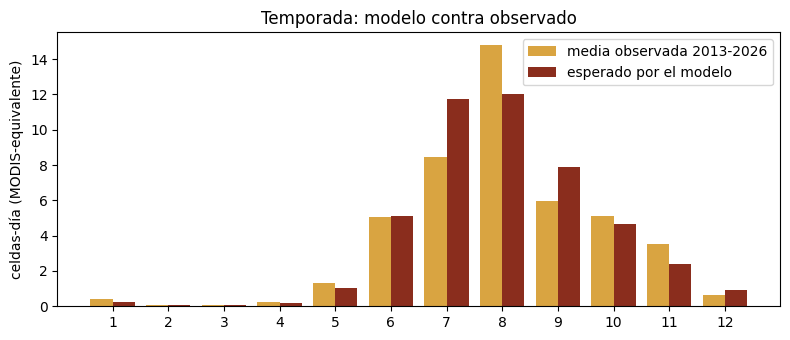

In [6]:
# Forma de la temporada que aprendió el modelo (época VIIRS) frente a lo observado
meses = pd.date_range("2027-01-01", periods=12, freq="MS")
forma = np.exp(disenio(meses).values @ aj_final.params.values)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(perfil.index - 0.2, perfil["mean"], width=0.4, color="#d9a441", label="media observada 2013-2026")
ax.bar(np.arange(1, 13) + 0.2, forma, width=0.4, color="#8a2d1d", label="esperado por el modelo")
ax.set_xticks(range(1, 13)); ax.set_ylabel("celdas-día (MODIS-equivalente)"); ax.legend(); ax.set_title("Temporada: modelo contra observado")
plt.tight_layout(); plt.show()

## 4. Validación rodante y métricas de desempeño

Cada año objetivo (2019–2026) se pronostica con el modelo entrenado **solo hasta octubre del año anterior**. Se comparan también dos referencias sin estadística:
**1a** (mismo mes del último año) y **1b** (mediana histórica del mes).

**Métricas** (celdas-día MODIS-equivalentes):

| Métrica | Qué dice |
|---|---|
| **MAE** | Error absoluto medio: cuánto se equivoca en promedio |
| **RMSE** | Raíz del error cuadrático medio: pesa más los meses con picos grandes |
| **MAPE** | Error porcentual medio. **No existe cuando el valor real es 0**; solo usa los meses con real > 0 y aun así es muy alto en lo mensual |
| **sMAPE** | MAPE simétrico: usa todos los meses, pero se infla con valores cercanos a 0 |
| **WAPE** | Error absoluto total ÷ total observado: la métrica más robusta con muchos ceros |
| **Sesgo** | Si en total pronostica de más (+) o de menos (−) |
| **Cobertura** | De cada 100 meses, cuántos reales cayeron dentro de la banda; el 90 % debería rondar 90 |

Las métricas **anuales** usan solo años completos (2019–2025); 2026 llega hasta octubre.

In [7]:
def pron_1a(d, fut):
    y = d.indice_para_alertas
    return pd.DataFrame({"esperado": [y[y.index.month == m.month].iloc[-1] for m in fut]}, index=fut)


def pron_1b(d, fut):
    g = d.indice_para_alertas.groupby(d.index.month)
    return pd.DataFrame({"esperado": [g.get_group(m.month).median() for m in fut],
                         "p05": [g.get_group(m.month).quantile(0.05) for m in fut],
                         "p95": [g.get_group(m.month).quantile(0.95) for m in fut]}, index=fut)


filas = []
for anio in range(2019, 2027):
    origen = pd.Timestamp(f"{anio - 1}-10-01")
    fin = min(pd.Timestamp(f"{anio}-12-01"), t.index.max())
    d = t.loc[:origen].dropna(subset=["indice_para_alertas"])
    fut = futuro(origen, fin)
    pb = pronosticar_bn(origen, fin)
    for nombre, df in (("2_binomial_negativa", pb), ("1a_ingenuo_mismo_mes", pron_1a(d, fut)), ("1b_mediana_historica_mes", pron_1b(d, fut))):
        df = df[df.index.year == anio]
        extra = df.assign(modelo=nombre, observado=t.loc[df.index, "indice_para_alertas"].values,
                          obs_conteo=t.loc[df.index, "conteo_base_alertas"].values, origen_hasta=origen,
                          horizonte_meses=(df.index.year - origen.year) * 12 + df.index.month - origen.month)
        filas.append(extra.reset_index(names="mes"))
bt = pd.concat(filas, ignore_index=True)
bt["anio"] = bt.mes.dt.year
print(f"Pronósticos evaluados: {len(bt)} ({bt.modelo.nunique()} modelos)")


def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    err, pos = pred - real, real > 0
    den = np.abs(real) + np.abs(pred)
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE %": 100 * np.mean(np.abs(err[pos]) / real[pos]) if pos.any() else np.nan, "meses con MAPE": int(pos.sum()),
            "sMAPE %": 100 * np.mean(np.where(den > 0, 2 * np.abs(err) / np.where(den > 0, den, 1), 0)),
            "WAPE %": 100 * np.abs(err).sum() / real.sum(), "sesgo %": 100 * err.sum() / real.sum()}


def tabla_metricas(df):
    filas = []
    for mod, g in df.groupby("modelo"):
        m = metricas(g.observado, g.esperado)
        a = g.groupby("anio")[["observado", "esperado"]].sum()[g.groupby("anio").size() == 12]
        an = metricas(a.observado, a.esperado)
        cub = g.dropna(subset=["p05"]) if "p05" in g else g.iloc[0:0]
        filas.append({"modelo": mod, **{k + " (mes)": v for k, v in m.items()},
                      "MAE (año)": an["MAE"], "RMSE (año)": an["RMSE"], "MAPE % (año)": an["MAPE %"], "WAPE % (año)": an["WAPE %"], "sesgo % (año)": an["sesgo %"],
                      "cobertura 90 %": 100 * ((cub.observado >= cub.p05) & (cub.observado <= cub.p95)).mean() if len(cub) else np.nan})
    return pd.DataFrame(filas).set_index("modelo").round(2)


metricas_tabla = tabla_metricas(bt)
metricas_tabla.T

Pronósticos evaluados: 282 (3 modelos)


modelo,1a_ingenuo_mismo_mes,1b_mediana_historica_mes,2_binomial_negativa
MAE (mes),3.58,2.99,2.41
RMSE (mes),6.51,5.74,4.78
MAPE % (mes),123.68,80.34,83.51
meses con MAPE (mes),67.00,67.00,67.00
sMAPE % (mes),93.31,88.24,103.53
WAPE % (mes),78.87,65.88,52.96
sesgo % (mes),-8.40,-61.20,-18.41
MAE (año),32.59,33.93,22.30
RMSE (año),36.88,41.00,26.32
MAPE % (año),73.81,54.92,41.21


Binomial negativa, por año (2026 llega hasta octubre):
      meses  observado  esperado  error  error %
anio                                            
2019     12       57.8      37.5  -20.3    -35.1
2020     12       94.4      39.8  -54.6    -57.9
2021     12       27.2      44.6   17.4     64.1
2022     12       68.3      43.8  -24.4    -35.8
2023     12       59.9      44.3  -15.6    -26.0
2024     12       40.0      48.2    8.1     20.3
2025     12       31.7      47.3   15.6     49.3
2026     10       47.7      42.9   -4.9    -10.2

Por horizonte:
              MAE  RMSE  WAPE %  sesgo %
horizonte                               
3-6 meses    0.21  0.29  139.22    -3.01
7-10 meses   4.38  6.96   51.01   -13.54
11-14 meses  2.64  4.46   53.74   -28.00


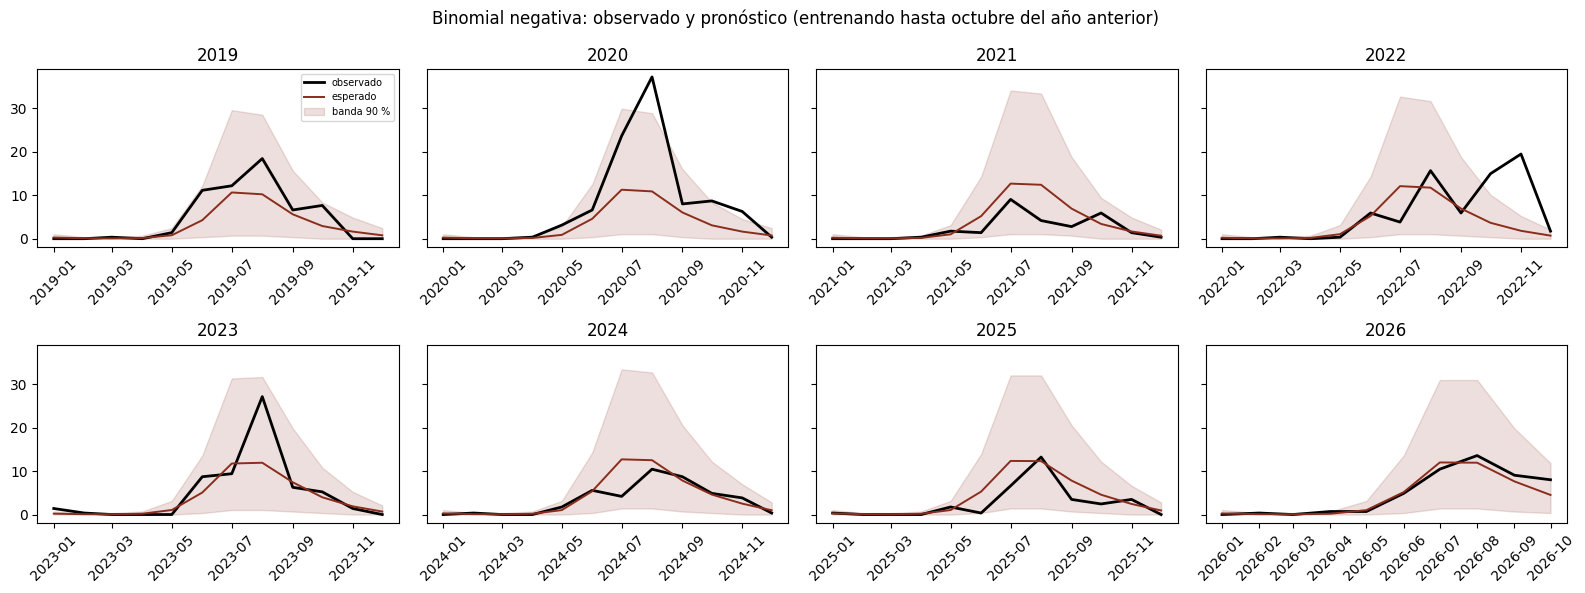

In [8]:
# Error por año completo: observado, esperado y error
a = bt[bt.modelo == "2_binomial_negativa"].groupby("anio").agg(meses=("observado", "size"), observado=("observado", "sum"), esperado=("esperado", "sum"))
a["error"] = a.esperado - a.observado
a["error %"] = 100 * a.error / a.observado
print("Binomial negativa, por año (2026 llega hasta octubre):")
print(a.round(1).to_string())

# Error según qué tan lejos está el mes pronosticado (horizonte en meses desde el corte)
b = bt[bt.modelo == "2_binomial_negativa"].copy()
b["horizonte"] = pd.cut(b.horizonte_meses, [2, 6, 10, 14], labels=["3-6 meses", "7-10 meses", "11-14 meses"])
print("\nPor horizonte:")
print(b.groupby("horizonte", observed=True).apply(lambda g: pd.Series(metricas(g.observado, g.esperado))).round(2)[["MAE", "RMSE", "WAPE %", "sesgo %"]].to_string())

fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharex=False, sharey=True)
for ax, (anio, g) in zip(axs.ravel(), bt[bt.modelo == "2_binomial_negativa"].groupby("anio")):
    ax.plot(g.mes, g.observado, "k-", lw=2, label="observado")
    ax.plot(g.mes, g.esperado, color="#8a2d1d", lw=1.4, label="esperado")
    ax.fill_between(g.mes, g.p05, g.p95, color="#8a2d1d", alpha=0.15, label="banda 90 %")
    ax.set_title(str(anio)); ax.tick_params(axis="x", labelrotation=45)
axs[0, 0].legend(fontsize=7)
plt.suptitle("Binomial negativa: observado y pronóstico (entrenando hasta octubre del año anterior)"); plt.tight_layout(); plt.show()

**Lectura de la validación:** en los meses lejanos al pico (noviembre a febrero) el valor real es casi siempre 0 o 1, así que el WAPE por horizonte sale enorme aunque el error absoluto (MAE) sea pequeño:
para esos tramos hay que mirar el MAE, no el porcentaje. Los años de temporada excepcional (2020) quedan muy por encima de lo pronosticado, y los años flojos (2021, 2025) por debajo: ese es el error anual de ≈ 41 %.

## 5. ¿Son confiables las bandas? (calibración)

Una banda del 90 % debería contener el valor real alrededor de 90 de cada 100 veces; una del 50 %, alrededor de 50. Además se hace el **histograma PIT**
(transformada integral de probabilidad aleatorizada): si el modelo está bien calibrado, es plano.

banda  cobertura observada %
 50 %                   59.6
 80 %                   88.3
 90 %                   91.5

Prueba de uniformidad del PIT (Kolmogorov–Smirnov): estadístico 0.104, p = 0.248 (no se rechaza la calibración)


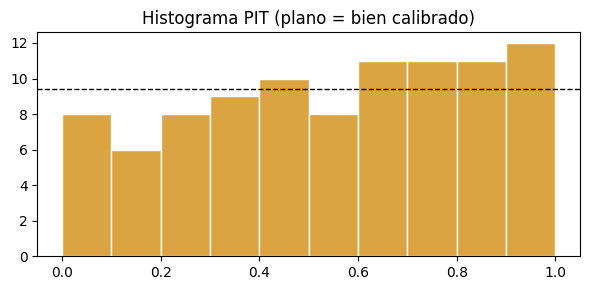

In [9]:
b = bt[bt.modelo == "2_binomial_negativa"].copy()
cob = []
for nombre, lo, hi in (("50 %", "p25", "p75"), ("80 %", "p10", "p90"), ("90 %", "p05", "p95")):
    cob.append({"banda": nombre, "cobertura observada %": 100 * ((b.observado >= b[lo]) & (b.observado <= b[hi])).mean()})
print(pd.DataFrame(cob).round(1).to_string(index=False))

# PIT aleatorizado sobre el conteo observado
yc, mu, r = b.obs_conteo.values, b.mu_cnt.values, b.r.values
p = r / (r + mu)
u = stats.nbinom.cdf(yc - 1, r, p) + RNG.random(len(yc)) * stats.nbinom.pmf(yc, r, p)
ks = stats.kstest(u, "uniform")
print(f"\nPrueba de uniformidad del PIT (Kolmogorov–Smirnov): estadístico {ks.statistic:.3f}, p = {ks.pvalue:.3f} ({'no se rechaza' if ks.pvalue > 0.05 else 'se rechaza'} la calibración)")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(u, bins=10, range=(0, 1), color="#d9a441", edgecolor="white"); ax.axhline(len(u) / 10, color="k", ls="--", lw=1)
ax.set_title("Histograma PIT (plano = bien calibrado)"); plt.tight_layout(); plt.show()

**Lectura de la calibración:** la banda del 90 % cumple (≈ 91 %) y el PIT no rechaza la calibración. Las bandas del 50 % y del 80 % salen algo **anchas** (cubren más de lo nominal): el modelo es algo conservador. Eso es preferible a prometer más certeza de la que hay.

## 6. Diagnóstico del ajuste

Se revisan los residuos de Pearson del modelo ajustado con **todos** los datos: no deberían tener estructura (ni correlación entre meses ni patrón contra el valor ajustado).

Ljung–Box sobre los residuos (H0: sin autocorrelación):
    lb_stat  lb_pvalue
12   46.133      0.000
24   52.427      0.001
Residuos de Pearson: media -0.03, desviación 1.17 (cercana a 1 si la dispersión está bien estimada)


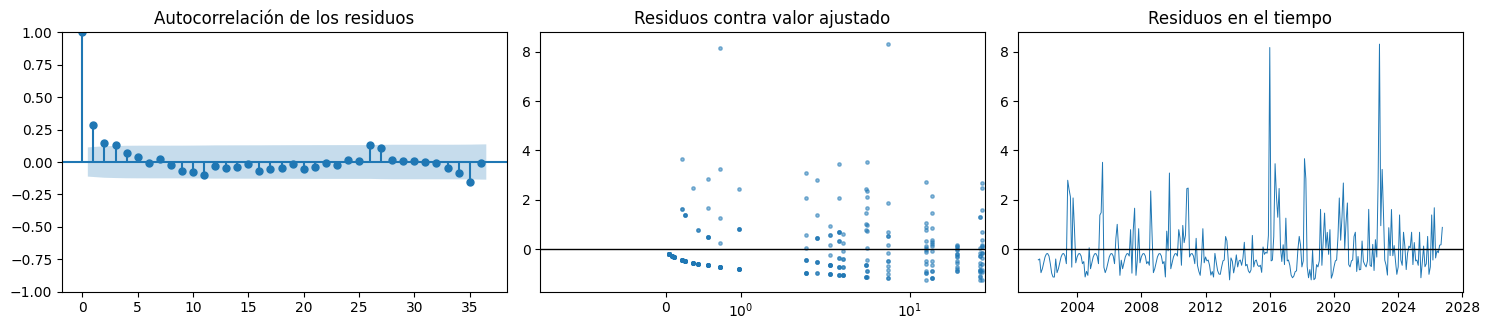

In [10]:
res = pd.Series(aj_final.resid_pearson, index=d_final.index)
lb = acorr_ljungbox(res, lags=[12, 24], return_df=True)
print("Ljung–Box sobre los residuos (H0: sin autocorrelación):")
print(lb.round(3).to_string())
print(f"Residuos de Pearson: media {res.mean():.2f}, desviación {res.std():.2f} (cercana a 1 si la dispersión está bien estimada)")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
plot_acf(res, lags=36, ax=ax[0]); ax[0].set_title("Autocorrelación de los residuos")
ax[1].scatter(aj_final.mu, res, s=6, alpha=0.5); ax[1].axhline(0, color="k", lw=1); ax[1].set_xscale("symlog"); ax[1].set_title("Residuos contra valor ajustado")
ax[2].plot(res.index, res.values, lw=0.7); ax[2].axhline(0, color="k", lw=1); ax[2].set_title("Residuos en el tiempo")
plt.tight_layout(); plt.show()

**Lectura del diagnóstico:** la media de los residuos es ≈ 0 y su desviación algo mayor que 1 (la dispersión podría estar apenas subestimada). La prueba de **Ljung–Box rechaza** que no haya autocorrelación:
queda algo de **persistencia entre meses** (una temporada fuerte tiende a seguir fuerte) que el modelo no captura porque solo usa el mes del año y la época. Esto es una **limitación conocida**: no invalida el pronóstico,
pero explica por qué el error anual sigue alto y por qué el modelo no «reacciona» a un año extremo. La variante SARIMA del notebook 10, que sí usa los meses anteriores, no mejoró el error anual.

## 7. Sensibilidad: ¿conviene cambiar la forma del modelo?

Se prueba con la misma validación rodante: 1, 2 o 3 armónicos, y la variante **con tendencia** (2b). Si ninguna mejora con claridad, se mantiene la elegida (`k = 2`, sin tendencia).

In [11]:
variantes = {"k=1 (sin tendencia)": dict(k=1), "k=2 (ELEGIDA)": dict(k=2), "k=3 (sin tendencia)": dict(k=3), "k=2 con tendencia": dict(k=2, tendencia=True)}
filas = []
for nombre, kw in variantes.items():
    partes = []
    for anio in range(2019, 2027):
        origen = pd.Timestamp(f"{anio - 1}-10-01")
        fin = min(pd.Timestamp(f"{anio}-12-01"), t.index.max())
        df = pronosticar_bn(origen, fin, **kw)
        df = df[df.index.year == anio]
        partes.append(df.assign(modelo=nombre, observado=t.loc[df.index, "indice_para_alertas"].values, anio=anio))
    filas.append(tabla_metricas(pd.concat(partes).reset_index(names="mes")))
sens = pd.concat(filas)[["MAE (mes)", "RMSE (mes)", "WAPE % (mes)", "MAE (año)", "WAPE % (año)", "sesgo % (año)", "cobertura 90 %"]]
sens

,MAE (mes),RMSE (mes),WAPE % (mes),MAE (año),WAPE % (año),sesgo % (año),cobertura 90 %
modelo,,,,,,,
k=1 (sin tendencia),2.46,4.84,54.21,22.74,41.96,-18.72,90.43
k=2 (ELEGIDA),2.41,4.78,52.96,22.30,41.16,-19.45,91.49
k=3 (sin tendencia),2.43,4.78,53.42,22.42,41.39,-19.59,91.49
k=2 con tendencia,3.10,5.45,68.31,25.17,46.46,22.15,95.74


## 8. Pronóstico hasta diciembre de 2031

Se entrena con **toda la serie hasta octubre de 2026** y se pronostican noviembre de 2026 a diciembre de 2031 (62 meses). El modelo es mensual: el último periodo es diciembre de 2031 completo.
**Importante:** el modelo no tiene tendencia, clima ni memoria del mes anterior, así que cada año futuro sale casi igual (un «año típico» con su banda). No dice qué año será fuerte o flojo; la sección 10 mide qué error tiene esto a 5 años.
Las bandas mensuales son las de la distribución binomial negativa; los **totales anuales** se simulan e incluyen también la incertidumbre de los parámetros.

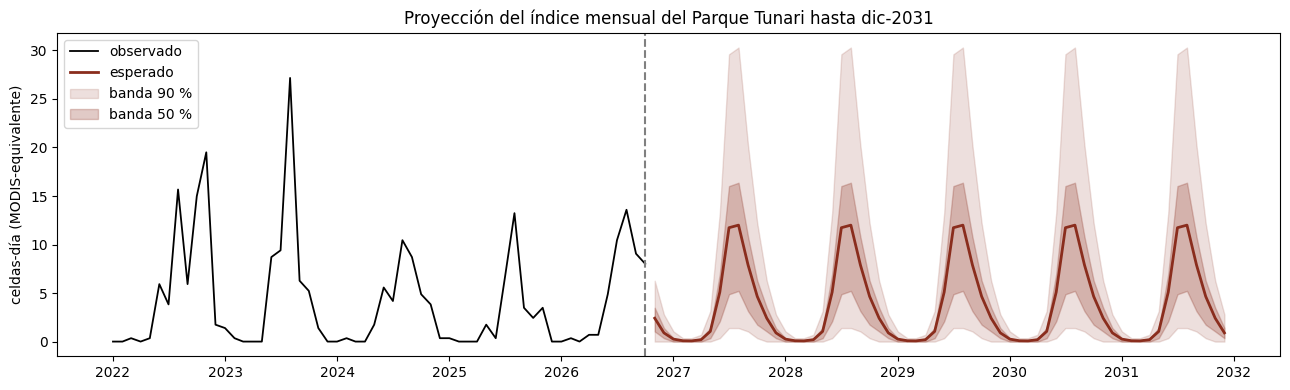

,indice_esperado,limite_inferior_p05,p25,p75,limite_superior_p95
mes,,,,,
2026-11-01,2.41,0.00,1.04,3.48,6.27
2026-12-01,0.90,0.00,0.35,1.39,2.79
2027-01-01,0.25,0.00,0.00,0.35,1.04
2027-02-01,0.09,0.00,0.00,0.00,0.35
2027-03-01,0.07,0.00,0.00,0.00,0.35
...,...,...,...,...,...
2031-08-01,12.00,1.39,5.22,16.37,30.30
2031-09-01,7.90,1.04,3.13,10.80,20.20
2031-10-01,4.65,0.35,1.74,6.27,12.19


In [12]:
FINAL = pd.Timestamp("2031-12-01")
pron = pronosticar_bn(ORIGEN, FINAL)
fut = pron.index
sim = simular(aj_final, alfa_final, fut)            # (simulaciones, meses)
mensual = pron[["esperado", "p05", "p25", "p75", "p95"]].copy()
mensual.columns = ["indice_esperado", "limite_inferior_p05", "p25", "p75", "limite_superior_p95"]
mensual = mensual.round(2)
mensual.index.name = "mes"

fig, ax = plt.subplots(figsize=(13, 4))
hist = t.loc["2022-01-01":, "indice_para_alertas"]
ax.plot(hist.index, hist.values, "k-", lw=1.3, label="observado")
ax.plot(fut, pron.esperado, color="#8a2d1d", lw=2, label="esperado")
ax.fill_between(fut, pron.p05, pron.p95, color="#8a2d1d", alpha=0.15, label="banda 90 %")
ax.fill_between(fut, pron.p25, pron.p75, color="#8a2d1d", alpha=0.25, label="banda 50 %")
ax.axvline(ORIGEN, color="gray", ls="--"); ax.set_ylabel("celdas-día (MODIS-equivalente)")
ax.set_title("Proyección del índice mensual del Parque Tunari hasta dic-2031"); ax.legend(); plt.tight_layout(); plt.show()
mensual

In [13]:
ref = anual.loc[2019:2025]
filas = []
periodos = [("nov-dic 2026", fut.year == 2026)] + [(str(a), fut.year == a) for a in range(2027, 2032)] + [("acumulado 2027-2031", fut.year >= 2027)]
for etiqueta, mask in periodos:
    tot = sim[:, mask].sum(axis=1)
    filas.append({"periodo": etiqueta, "esperado (media)": tot.mean(), "mediana": np.median(tot), "p05": np.quantile(tot, 0.05), "p95": np.quantile(tot, 0.95)})
anual_pron = pd.DataFrame(filas).set_index("periodo").round(1)
print(anual_pron.to_string())
tot27 = sim[:, fut.year == 2027].sum(axis=1)
print(f"\nAcumulado 2027-2031 esperado {sim[:, fut.year >= 2027].sum(axis=1).mean():.0f} contra {5 * ref.mean():.0f} si cada año fuera igual a la media 2019-2025")
print(f"\nReferencia 2019-2025: media {ref.mean():.1f}, mínimo {ref.min():.1f} ({ref.idxmin()}), máximo {ref.max():.1f} ({ref.idxmax()})")
print(f"Probabilidad de que 2027 supere la media 2019-2025: {np.mean(tot27 > ref.mean()):.0%}")
print(f"Probabilidad de que 2027 supere {ref.max():.0f} celdas-día (el máximo reciente): {np.mean(tot27 > ref.max()):.0%}")
print(f"Probabilidad de que 2027 sea menor que {ref.min():.0f} (el mínimo reciente): {np.mean(tot27 < ref.min()):.0%}")

# ¿Qué tan bien cubre esta banda ANUAL con simulación? (años completos 2019-2025, entrenando hasta octubre previo)
chk = []
for anio in range(2019, 2026):
    origen = pd.Timestamp(f"{anio - 1}-10-01")
    d = t.loc[:origen].dropna(subset=["indice_para_alertas"])
    aj, al = ajustar_bn(d)
    f = pd.date_range(f"{anio}-01-01", f"{anio}-12-01", freq="MS")
    s = simular(aj, al, f, n=4000).sum(axis=1)
    obs = t.loc[f, "indice_para_alertas"].sum()
    chk.append({"año": anio, "observado": obs, "p05": np.quantile(s, 0.05), "mediana": np.median(s), "p95": np.quantile(s, 0.95)})
chk = pd.DataFrame(chk).set_index("año").round(1)
chk["¿dentro de la banda 90 %?"] = (chk.observado >= chk.p05) & (chk.observado <= chk.p95)
print("\nComprobación de la banda anual (simulada) en los años pasados:")
print(chk.to_string())

                     esperado (media)  mediana    p05    p95
periodo                                                     
nov-dic 2026                      3.3      2.8    0.7    7.7
2027                             46.8     44.2   24.0   77.0
2028                             46.7     44.6   24.0   77.3
2029                             46.6     44.2   24.0   77.0
2030                             46.9     44.6   24.4   77.0
2031                             46.6     44.2   23.7   77.0
acumulado 2027-2031             233.6    230.5  171.7  305.1

Acumulado 2027-2031 esperado 234 contra 271 si cada año fuera igual a la media 2019-2025

Referencia 2019-2025: media 54.2, mínimo 27.2 (2021), máximo 94.4 (2020)
Probabilidad de que 2027 supere la media 2019-2025: 29%
Probabilidad de que 2027 supere 94 celdas-día (el máximo reciente): 1%
Probabilidad de que 2027 sea menor que 27 (el mínimo reciente): 9%

Comprobación de la banda anual (simulada) en los años pasados:
      observado   p05  median

### Cómo leer el pronóstico

- La **línea** es el valor esperado; las **bandas** dicen dónde caería el real el 50 % y el 90 % de las veces. Hay que mostrarlas siempre: la cifra sola promete más certeza de la que hay.
- El tamaño de la temporada cambia mucho de un año a otro (2020 fue enorme y 2021 pequeña). Ese salto **no se puede adivinar** con solo la historia de la serie; por eso la banda anual es ancha.
- El modelo tiende a **subestimar los años extremos** (sesgo negativo en la validación): úsese la banda alta como escenario de «temporada intensa».

## 9. Sensibilidad a los datos provisionales (NRT)

Agosto–octubre de 2026 son datos NRT. Se repite el pronóstico **sin esos tres meses** (entrenando hasta julio de 2026) para ver cuánto cambia el total de 2027.

In [14]:
pron_sin = pronosticar_bn(pd.Timestamp("2026-07-01"), FINAL)
a_ = pron[pron.index.year == 2027].esperado.sum()
b_ = pron_sin[pron_sin.index.year == 2027].esperado.sum()
print(f"Total esperado 2027 con datos hasta oct-2026 (incluye NRT): {a_:.1f}")
print(f"Total esperado 2027 con datos hasta jul-2026 (sin NRT):      {b_:.1f}")
print(f"Diferencia: {a_ - b_:+.1f} celdas-día ({100 * (a_ - b_) / b_:+.1f} %)")

Total esperado 2027 con datos hasta oct-2026 (incluye NRT): 46.3
Total esperado 2027 con datos hasta jul-2026 (sin NRT):      46.0
Diferencia: +0.4 celdas-día (+0.8 %)


## 10. Validación a horizonte largo (hasta 5 años)

La validación anterior llega a 14 meses. Como ahora se proyecta a **5 años**, se repite con ventanas largas: se entrena hasta octubre de 2016, 2017, … 2021 y se pronostican los **60 meses siguientes**
(solo se pueden evaluar los que ya ocurrieron hasta octubre de 2026). Se mide el total de cada ventana de 12 meses (noviembre–octubre): 1.er año adelante, 2.º año, … 5.º año.
Las ventanas de distintos orígenes se **solapan** y son pocas: son una guía, no una prueba definitiva.

In [15]:
filas = []
for anio_o in range(2016, 2022):
    origen = pd.Timestamp(f"{anio_o}-10-01")
    fin = min(origen + pd.DateOffset(months=60), t.index.max())
    pb = pronosticar_bn(origen, fin)
    simu = simular(pb.attrs["ajuste"], pb.attrs["alfa"], pb.index, n=4000)
    for k in range(5):
        sl = slice(12 * k, 12 * k + 12)
        idx = pb.index[sl]
        if len(idx) < 12:
            continue
        tot = simu[:, sl].sum(axis=1)
        obs_m = t.loc[idx, "indice_para_alertas"].values
        filas.append({"origen": origen.strftime("%Y-%m"), "año adelante": k + 1, "observado": obs_m.sum(), "esperado": pb.esperado.iloc[sl].sum(),
                      "p05": np.quantile(tot, 0.05), "p95": np.quantile(tot, 0.95), "MAE mensual": np.mean(np.abs(pb.esperado.iloc[sl].values - obs_m))})
lh = pd.DataFrame(filas)
lh["dentro de la banda 90 %"] = (lh.observado >= lh.p05) & (lh.observado <= lh.p95)
resumen_lh = lh.groupby("año adelante").apply(lambda g: pd.Series({
    "ventanas": len(g), "MAE anual": np.mean(np.abs(g.esperado - g.observado)), "WAPE anual %": 100 * np.abs(g.esperado - g.observado).sum() / g.observado.sum(),
    "sesgo %": 100 * (g.esperado - g.observado).sum() / g.observado.sum(), "MAE mensual": g["MAE mensual"].mean(), "cobertura banda 90 %": 100 * g["dentro de la banda 90 %"].mean()})).round(1)
print(lh.round(1).to_string(index=False))
print("\nResumen por año adelante:")
print(resumen_lh.to_string())

 origen  año adelante  observado  esperado  p05  p95  MAE mensual  dentro de la banda 90 %
2016-10             1       16.4      43.9 20.5 79.1          2.8                    False
2016-10             2       19.2      43.9 20.2 80.1          2.9                    False
2016-10             3       58.2      43.9 20.5 78.4          1.9                     True
2016-10             4       87.8      43.9 20.9 80.8          4.1                    False
2016-10             5       32.0      43.9 20.5 78.7          2.4                     True
2017-10             1       19.2      40.3 18.1 75.6          2.7                     True
2017-10             2       58.2      40.3 18.8 74.9          2.0                     True
2017-10             3       87.8      40.3 18.5 75.2          4.4                    False
2017-10             4       32.0      40.3 17.4 74.5          2.2                     True
2017-10             5       48.8      40.3 18.5 73.8          2.4                     True

**Cómo leerlo:** si el error del 4.º y 5.º año es parecido al del 1.º, el modelo no se degrada con el horizonte (lógico: no usa memoria del pasado reciente, siempre pronostica el «año típico»).
Eso **no significa que acierte**: significa que tiene un error parecido, de alrededor del 40 %, a cualquier horizonte. Si la cobertura de la banda del 90 % queda por debajo de lo esperado, hay que presentar la banda como **optimista**.

## 11. Noviembre de 2026 en adelante: NOAA-20 en lugar de Suomi-NPP

Suomi-NPP **dejó de entregar datos** (el último archivo de FIRMS está vacío). Desde noviembre de 2026 el conteo mensual debe salir de **NOAA-20**, convertido a la escala de Suomi-NPP con el **factor de enlace**
(`celdas-día de Suomi-NPP equivalentes = celdas-día de NOAA-20 ÷ enlace`; enlace ≈ 1,0, rango 0,94–1,10 medido en el Tunari) y luego dividido por el factor VIIRS/MODIS.
Primero se compara la relación en los meses con ambos satélites y se ve qué hay de noviembre hasta ahora.

In [16]:
cols = ["fecha_bo", "fuente", "cell_id", "en_parque_tunari"]
dn = pd.concat([pd.read_csv(PAQUETE / "detecciones.csv", usecols=cols), pd.read_csv(PAQUETE.parent / "datos_prueba" / "detecciones_2026.csv", usecols=cols)])
dn = dn[dn.en_parque_tunari & dn.fuente.isin(["VIIRS-Suomi-NPP", "VIIRS-NOAA-20"]) & (dn.fecha_bo >= "2026-08-01")].drop_duplicates(["fuente", "fecha_bo", "cell_id"])
dn["mes"] = dn.fecha_bo.str[:7]
cmp_ = dn.groupby(["mes", "fuente"]).size().unstack(fill_value=0)
cmp_["NOAA-20 / Suomi-NPP"] = (cmp_["VIIRS-NOAA-20"] / cmp_["VIIRS-Suomi-NPP"].replace(0, np.nan)).round(2)
print("Celdas-día en el parque por satélite (el último día con datos de noviembre en el paquete es el 11):")
print(cmp_.to_string())


def indice_desde_noaa20(conteo_noaa20, enlace=1.0):
    return np.asarray(conteo_noaa20, float) / (enlace * FACTOR)


n20_nov = int(cmp_.loc["2026-11", "VIIRS-NOAA-20"]) if "2026-11" in cmp_.index else 0
ej = pd.DataFrame({"enlace": [0.94, 1.00, 1.10]})
ej["celdas-día Suomi equivalentes"] = (n20_nov / ej.enlace).round(1)
ej["índice de noviembre a la fecha"] = indice_desde_noaa20(n20_nov, ej.enlace).round(2)
print(f"\nNoviembre a la fecha: {n20_nov} celdas-día de NOAA-20")
ej

Celdas-día en el parque por satélite (el último día con datos de noviembre en el paquete es el 11):
fuente   VIIRS-NOAA-20  VIIRS-Suomi-NPP  NOAA-20 / Suomi-NPP
mes                                                         
2026-08             46               39                 1.18
2026-09             31               26                 1.19
2026-10             25               23                 1.09
2026-11              3                0                  NaN

Noviembre a la fecha: 3 celdas-día de NOAA-20


,enlace,celdas-día Suomi equivalentes,índice de noviembre a la fecha
0,0.94,3.2,1.11
1,1.00,3.0,1.04
2,1.10,2.7,0.95


**Cómo entra noviembre al modelo:**

- Noviembre **aún no está cerrado**, así que **no se agrega al entrenamiento**: el pronóstico usa datos hasta octubre (de Suomi-NPP) y pronostica noviembre como un mes más.
- **Cuando cierre noviembre** (desde el 1 de diciembre), su conteo se calcula con NOAA-20 ÷ enlace y se agrega a la serie; cada mes nuevo entra igual. Después se vuelve a ejecutar este notebook.
- El enlace central es **1,0**; para mostrar la incertidumbre se repiten los pronósticos con 0,94 y 1,10 (el efecto es pequeño: un mes con 20 celdas-día de NOAA-20 vale entre 6,3 y 7,4 de índice).
- **Ojo con el enlace:** mire la columna «NOAA-20 / Suomi-NPP» de la tabla. El valor histórico (2018–2025) es ≈ 0,99, pero en los meses recientes del parque NOAA-20 aparece con **más** celdas-día que Suomi-NPP. Con pocos días el cociente es ruidoso (y esos meses son NRT), pero si se mantiene por encima de 1,1 hay que **reajustar el enlace con datos de 2026** antes de usarlo; mientras tanto, el escenario 1,10 es el que hay que mirar como sensibilidad (baja el índice de los meses con NOAA-20).
- Suomi-NPP **no se vuelve a usar** para meses nuevos.

## 12. Cuando llegue información nueva

El modelo se vuelve a ajustar **cada vez que se agreguen meses a `serie_mensual`**:

1. Se actualizan los datos y el paquete (`python actualizar_todo.py`).
2. Se vuelve a ejecutar este notebook: `ORIGEN` toma el último mes de la serie y el pronóstico se recalcula solo.
3. Se mira la tabla de la sección 1 para saber cuántos de los últimos meses siguen siendo provisionales.

**Pendiente importante: el enlace con NOAA-20.** Suomi-NPP terminó en noviembre de 2026. NOAA-20 la continúa con un factor de enlace ≈ 1,0 (rango 0,94–1,10, medido en el Tunari), pero **todavía no está aplicado en el pipeline**.
Cuando se aplique, un mes de 2026 en adelante pasará de conteo NOAA-20 a índice así:

In [17]:
def indice_desde_noaa20(conteo_noaa20, enlace=1.0):
    # celdas-día de Suomi-NPP equivalentes = NOAA-20 / enlace; luego se divide por el factor VIIRS/MODIS
    return np.asarray(conteo_noaa20, float) / (enlace * FACTOR)


ej = pd.DataFrame({"enlace": [0.94, 1.00, 1.10]})
ej["índice de un mes con 20 celdas-día de NOAA-20"] = indice_desde_noaa20(20, ej.enlace).round(2)
ej

,enlace,índice de un mes con 20 celdas-día de NOAA-20
0,0.94,7.41
1,1.00,6.97
2,1.10,6.33


## 13. Guardar las salidas

Se guardan archivos nuevos con el prefijo `bn_` (no se tocan los del notebook 09).

In [18]:
pron_out = mensual.reset_index()
pron_out.insert(0, "area_id", AREA)
pron_out["anio"], pron_out["mes_num"] = pron_out.mes.dt.year, pron_out.mes.dt.month
pron_out["modelo"] = "2_binomial_negativa"
pron_out["horizonte_meses"] = (pron_out.anio - ORIGEN.year) * 12 + pron_out.mes_num - ORIGEN.month
pron_out["origen_hasta"] = ORIGEN.strftime("%Y-%m-%d")
pron_out["calidad_indice"] = "calibrado_localmente_en_tunari"
pron_out.to_csv(SALIDA / "bn_pronostico_mensual_tunari.csv", index=False)
anual_pron.to_csv(SALIDA / "bn_pronostico_anual_tunari.csv")
metricas_tabla.to_csv(SALIDA / "bn_metricas_desempeno_tunari.csv")
bt.drop(columns=["mu_cnt", "r", "anio"]).to_csv(SALIDA / "bn_validacion_rodante_tunari.csv", index=False)
import json

(SALIDA / "bn_parametros_tunari.json").write_text(json.dumps({"modelo": "2_binomial_negativa", "dispersion_alfa": round(float(alfa_final), 4), "factor_viirs_por_modis": FACTOR,
                                                              "origen_hasta": ORIGEN.strftime("%Y-%m-%d"), "horizonte_hasta": FINAL.strftime("%Y-%m-%d")}, indent=2), encoding="utf-8")
print("Guardado en", SALIDA)
print([p.name for p in sorted(SALIDA.glob("bn_*"))])

Guardado en DATOS_PROCESADOS\pronostico
['bn_metricas_desempeno_tunari.csv', 'bn_parametros_tunari.json', 'bn_pronostico_anual_tunari.csv', 'bn_pronostico_mensual_tunari.csv', 'bn_validacion_rodante_tunari.csv']


## 14. Límites que hay que decir en voz alta

1. **Pronosticamos el nivel típico, no cada incendio.** El modelo dice cuánta actividad de calor esperar en el mes; no cuándo ni dónde empieza un fuego.
2. **La variación entre años domina.** Con 13 temporadas VIIRS, el tamaño de la temporada de 2027 es muy incierto; las bandas son anchas a propósito.
3. **El error anual medido ronda el 41 %** y el modelo tiende a quedarse corto en los años extremos. Es una referencia, no una cifra exacta.
4. **No usa clima.** La lluvia o la sequía cambian mucho la temporada; incorporar clima solo ayuda si se conoce de antemano (en la prueba, con el clima real mejoró, pero eso no es un pronóstico).
5. **Los últimos tres meses son provisionales (NRT)** y pueden cambiar cuando NASA publique el dato estándar (ver sección 9).
6. **Suomi-NPP terminó.** El enlace con NOAA-20 está medido pero no aplicado; hasta que lo esté, los datos nuevos no entran a la serie.
7. **Las bandas anuales simuladas son aproximadas:** suponen que los coeficientes se distribuyen normalmente y que la dispersión es fija.
8. **El factor de armonización (2,8715) se ajustó con 2013–2025,** así que la validación contiene una fuga leve de información posterior a cada corte. Afecta por igual a todos los modelos comparados.
9. **Una detección satelital de calor no es un incendio confirmado.**